# Loanliness: improved model (beyond the paper)

`loan_pipeline.ipynb` and `loan_models.ipynb` reproduce the paper. This notebook is the one departure from it: a single LightGBM that scores higher on the same train / test split. It changes four things relative to the paper protocol:

1. **All train rows.** No down-sampling; the imbalance is handled with `scale_pos_weight`, and the decision threshold is chosen from out-of-fold predictions on the train set.
2. **Raw missing values and ratio features.** No 30% column drop and no mean imputation (LightGBM takes the NaNs and the categorical columns directly), plus six ratios of application columns.
3. **`EXT_SOURCE_1..3` restored.** The paper excludes these three external credit scores. Results are given for two feature sets: the new features **with `EXT_SOURCE`** (837 columns) and the same table **without `EXT_SOURCE`** (834 columns). The second still respects the paper's exclusion.
4. **Tuned LightGBM.** Random search with early stopping, then a final fit at a lower learning rate.

The rows, the split and the balanced test set are the ones saved by `loan_pipeline.ipynb`, matched by `SK_ID_CURR`, so the scores are directly comparable with `loan_models.ipynb`. Run those two notebooks first. The test sets are used only for the final scores.

## 0. Setup

In [1]:
import gc, json, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split

from loan_utils import ARTIFACTS as OUT, SEED, class_weights, load_split, metrics

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
DATA = Path("dataset")

X_base, y = load_split("train")
Xt_base, yt = load_split("test")
bal_ids = load_split("test_balanced")[0].index
cw = class_weights(y); spw = cw[1] / cw[0]
folds = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(X_base, y))
tr_i, va_i = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
print(X_base.shape, Xt_base.shape, len(bal_ids))

(246008, 700) (61503, 700) 9930


## 1. Raw joined table and ratio features

Same joins and aggregations as section 1 of `loan_pipeline.ipynb` (the code is copied from there), with the same two stateless fixes: the `DAYS_EMPLOYED` placeholder becomes NaN plus a flag, and record counts are 0 for clients with no history. Nothing is dropped, imputed, encoded or scaled. The table is cached in `artifacts/train_raw.parquet` and `test_raw.parquet`, in the row order of the saved splits.

The ratios are computed row by row from application columns, so nothing is learned from the data.

In [2]:
def agg_table(df, key, prefix, drop_cols=()):
    # numeric -> mean/min/max/sum, categorical -> one-hot then mean (share) and sum (count)
    df = df.drop(columns=list(drop_cols), errors="ignore")
    cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c != key]
    num = df.drop(columns=cat_cols)
    num_cols = [c for c in num.columns if c != key]
    parts = [num.groupby(key)[num_cols].agg(["mean", "min", "max", "sum"])]
    if cat_cols:
        dummies = pd.get_dummies(df[cat_cols], dtype="float32", dummy_na=False)
        dummies[key] = df[key].values
        parts.append(dummies.groupby(key).agg(["mean", "sum"]))
    out = pd.concat(parts, axis=1)
    out.columns = [f"{prefix}_{a}_{b}".replace(" ", "_") for a, b in out.columns]
    out[f"{prefix}_COUNT"] = df.groupby(key).size().astype("float32")
    return out.astype("float32")

def read(name, **kw):
    df = pd.read_csv(DATA / name, **kw)
    for c in df.select_dtypes("float64").columns:
        df[c] = df[c].astype("float32")
    return df

def build_raw():
    bb = read("bureau_balance.csv"); bb_agg = agg_table(bb, "SK_ID_BUREAU", "bb"); del bb
    bureau = read("bureau.csv").merge(bb_agg, left_on="SK_ID_BUREAU", right_index=True, how="left")
    aggs = [agg_table(bureau, "SK_ID_CURR", "bureau", drop_cols=["SK_ID_BUREAU"])]; del bureau, bb_agg; gc.collect()

    prev = read("previous_application.csv")
    day_cols = [c for c in prev.columns if c.startswith("DAYS_")]
    prev[day_cols] = prev[day_cols].replace(365243, np.nan)
    aggs.append(agg_table(prev, "SK_ID_CURR", "prev", drop_cols=["SK_ID_PREV"])); del prev; gc.collect()

    pos = read("POS_CASH_balance.csv")
    a = agg_table(pos, "SK_ID_CURR", "pos", drop_cols=["SK_ID_PREV"])
    a["pos_N_LOANS"] = pos.groupby("SK_ID_CURR")["SK_ID_PREV"].nunique().astype("float32")
    aggs.append(a); del pos; gc.collect()

    inst = read("installments_payments.csv")
    inst["DAYS_PAST_DUE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]
    inst["PAYMENT_DIFF"] = inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]
    aggs.append(agg_table(inst, "SK_ID_CURR", "inst", drop_cols=["SK_ID_PREV"])); del inst; gc.collect()

    cc = read("credit_card_balance.csv")
    aggs.append(agg_table(cc, "SK_ID_CURR", "cc", drop_cols=["SK_ID_PREV"])); del cc; gc.collect()

    df = read("application_train.csv")
    df = df.rename(columns={c: f"app_{c}" for c in df.columns if c not in ("SK_ID_CURR", "TARGET")})
    for a in aggs:
        df = df.merge(a, left_on="SK_ID_CURR", right_index=True, how="left")
    df["app_DAYS_EMPLOYED_ANOM"] = (df["app_DAYS_EMPLOYED"] == 365243).astype("float32")
    df["app_DAYS_EMPLOYED"] = df["app_DAYS_EMPLOYED"].replace(365243, np.nan)
    count_cols = [c for c in df.columns if c.endswith(("_COUNT", "_N_LOANS"))]
    df[count_cols] = df[count_cols].fillna(0)
    df.columns = [re.sub(r"[^0-9a-zA-Z_]", "_", c) for c in df.columns]
    assert df.columns.is_unique
    return df.set_index("SK_ID_CURR")

if not (OUT / "train_raw.parquet").exists():
    t0 = time.time(); raw = build_raw()
    raw.loc[X_base.index].to_parquet(OUT / "train_raw.parquet"); raw.loc[Xt_base.index].to_parquet(OUT / "test_raw.parquet")
    del raw; gc.collect(); print(f"built in {time.time() - t0:.0f}s")

R, Rt = pd.read_parquet(OUT / "train_raw.parquet"), pd.read_parquet(OUT / "test_raw.parquet")
# same rows, same order and same labels as the saved splits
assert R.index.equals(X_base.index) and Rt.index.equals(Xt_base.index)
assert (R.pop("TARGET").to_numpy() == y.to_numpy()).all() and (Rt.pop("TARGET").to_numpy() == yt.to_numpy()).all()
for c in R.select_dtypes(exclude="number").columns:   # categories fixed on train; unseen test levels become NaN
    R[c] = R[c].astype("category"); Rt[c] = pd.Categorical(Rt[c], categories=R[c].cat.categories)

def add_ratios(d):
    r = {"ratio_CREDIT_INCOME": d["app_AMT_CREDIT"] / d["app_AMT_INCOME_TOTAL"],
         "ratio_ANNUITY_INCOME": d["app_AMT_ANNUITY"] / d["app_AMT_INCOME_TOTAL"],
         "ratio_ANNUITY_CREDIT": d["app_AMT_ANNUITY"] / d["app_AMT_CREDIT"],            # inverse of the loan term
         "ratio_CREDIT_GOODS": d["app_AMT_CREDIT"] / d["app_AMT_GOODS_PRICE"],
         "ratio_EMPLOYED_BIRTH": d["app_DAYS_EMPLOYED"] / d["app_DAYS_BIRTH"],           # share of life employed
         "ratio_INCOME_PER_PERSON": d["app_AMT_INCOME_TOTAL"] / d["app_CNT_FAM_MEMBERS"]}
    return d.join(pd.DataFrame(r).replace([np.inf, -np.inf], np.nan).astype("float32"))

Xnew, Xnew_t = add_ratios(R), add_ratios(Rt)
ext = [c for c in Xnew.columns if "EXT_SOURCE" in c]
ratio_cols = [c for c in Xnew.columns if c.startswith("ratio_")]
noext = [c for c in Xnew.columns if c not in ext]
del R, Rt, X_base, Xt_base; gc.collect()
print(Xnew.shape, "| categorical:", (Xnew.dtypes == "category").sum(), "| missing cells:", f"{Xnew.isna().mean().mean():.1%}")
Xnew[ext].isna().mean().round(3)

(246008, 837) | categorical: 16 | missing cells: 23.3%


app_EXT_SOURCE_1    0.563
app_EXT_SOURCE_2    0.002
app_EXT_SOURCE_3    0.198
dtype: float64

## 2. Random search

Stratified 80/20 split of the train set. Each configuration trains at learning rate 0.1 and stops when validation AUC has not improved for 50 rounds. Row 0 is the configuration used in `loan_models.ipynb` (31 leaves, everything else default), for reference.

In [3]:
def fit_es(Xa, ya, Xv, yv, params, lr, patience):
    # metric="auc" only: with a weighted positive class the default log-loss on the validation rows rises from round 1 and would stop training at once
    m = LGBMClassifier(n_estimators=5000, learning_rate=lr, scale_pos_weight=spw, metric="auc", random_state=SEED, n_jobs=10, verbosity=-1, **params)
    return m.fit(Xa, ya, eval_X=Xv, eval_y=yv, callbacks=[lgb.early_stopping(patience, verbose=False)])

rng = np.random.default_rng(SEED)
def sample():
    return dict(num_leaves=int(rng.choice([15, 23, 31, 47, 63])), max_depth=int(rng.choice([-1, 6, 8])),
                min_child_samples=int(rng.choice([20, 50, 100, 200, 400])), colsample_bytree=float(rng.choice([0.2, 0.3, 0.5, 0.7])),
                subsample=float(rng.choice([0.6, 0.8, 1.0])), subsample_freq=1,
                reg_lambda=float(rng.choice([0, 1, 5, 20])), reg_alpha=float(rng.choice([0, 0.1, 1])), min_split_gain=float(rng.choice([0, 0.02, 0.1])))

Xa, ya, Xv, yv = Xnew.iloc[tr_i], y.iloc[tr_i], Xnew.iloc[va_i], y.iloc[va_i]
rows = []
for p in [dict(num_leaves=31)] + [sample() for _ in range(20)]:
    t0 = time.time(); m = fit_es(Xa, ya, Xv, yv, p, 0.1, 50)
    rows.append({**p, "trees": m.best_iteration_, "val AUC": m.best_score_["valid_0"]["auc"], "secs": round(time.time() - t0)})
search = pd.DataFrame(rows); search.to_csv(OUT / "lgbm_search.csv", index=False)

keys = ["num_leaves", "max_depth", "min_child_samples", "colsample_bytree", "subsample", "subsample_freq", "reg_lambda", "reg_alpha", "min_split_gain"]
b = search.iloc[1:].sort_values("val AUC").iloc[-1]
best = {k: (int(b[k]) if k in ("num_leaves", "max_depth", "min_child_samples", "subsample_freq") else float(b[k])) for k in keys}
json.dump(best, open(OUT / "lgbm_best_params.json", "w"))
print("best:", best); print("reference val AUC:", round(search.iloc[0]["val AUC"], 4), "| best:", round(b["val AUC"], 4))
search.sort_values("val AUC", ascending=False).round(4).head(8)

best: {'num_leaves': 23, 'max_depth': 8, 'min_child_samples': 200, 'colsample_bytree': 0.2, 'subsample': 1.0, 'subsample_freq': 1, 'reg_lambda': 0.0, 'reg_alpha': 1.0, 'min_split_gain': 0.0}
reference val AUC: 0.7806 | best: 0.7838


,num_leaves,trees,val AUC,secs,max_depth,min_child_samples,colsample_bytree,subsample,subsample_freq,reg_lambda,reg_alpha,min_split_gain
13,23,233,0.7838,14,8.0,200.0,0.2,1.0,1.0,0.0,1.0,0.00
5,15,332,0.7837,16,6.0,400.0,0.2,1.0,1.0,20.0,0.0,0.02
1,15,441,0.7836,24,8.0,200.0,0.3,0.8,1.0,20.0,0.0,0.10
2,23,186,0.7833,13,-1.0,100.0,0.7,1.0,1.0,20.0,1.0,0.10
16,31,159,0.7829,14,8.0,200.0,0.3,1.0,1.0,5.0,0.0,0.10
6,15,207,0.7829,13,8.0,200.0,0.3,0.6,1.0,20.0,0.1,0.10
8,31,142,0.7827,15,-1.0,200.0,0.5,1.0,1.0,5.0,0.1,0.10
19,63,166,0.7820,13,8.0,20.0,0.2,1.0,1.0,0.0,1.0,0.00


In [4]:
# which settings matter: validation AUC by value
pd.concat({k: search.iloc[1:].groupby(k)["val AUC"].agg(["mean", "max", "count"]) for k in ["num_leaves", "min_child_samples", "colsample_bytree", "subsample"]}).round(4)

mean     max  count
num_leaves        15.0   0.7834  0.7837      3
                  23.0   0.7835  0.7838      2
                  31.0   0.7803  0.7829      7
                  47.0   0.7805  0.7819      5
                  63.0   0.7782  0.7820      3
min_child_samples 20.0   0.7796  0.7820      2
                  50.0   0.7819  0.7819      1
                  100.0  0.7793  0.7833      6
                  200.0  0.7818  0.7838      8
                  400.0  0.7816  0.7837      3
colsample_bytree  0.2    0.7822  0.7838      4
                  0.3    0.7816  0.7836      7
                  0.5    0.7789  0.7827      5
                  0.7    0.7804  0.7833      4
subsample         0.6    0.7789  0.7829      6
                  0.8    0.7802  0.7836      6
                  1.0    0.7827  0.7838      8

**Findings.** The search range is narrow: the 20 configurations span 0.775 to 0.784 validation AUC, and the reference settings sit in the middle at 0.781. The best configuration (23 leaves, depth 8, `min_child_samples=200`, `colsample_bytree=0.2`, `reg_alpha=1`) gains 0.003. The top six are within 0.001 of each other, so the exact winner is not meaningful, but the pattern is consistent: small trees (15 to 23 leaves average 0.783, 63 leaves 0.778), larger leaves and a low column fraction. With 837 mostly weak features, simpler trees that each see a fifth of the columns generalise better. Row subsampling below 1.0 did not help.

## 3. Final fit, 3-fold out-of-fold

The best configuration at learning rate 0.02. In each fold 10% of the training rows are held back for early stopping (patience 100); the fold's own validation part is never seen during fitting. Out-of-fold predictions give the threshold (largest TPR minus FPR), and test predictions are the mean of the three fold models.

Two reference rows use the settings of `loan_models.ipynb` (300 trees, learning rate 0.05, 31 leaves) on all train rows: the new features with `EXT_SOURCE`, untuned, which isolates what tuning adds, and the paper's 700 features, which isolates what the new features add.

In [5]:
def run_cv(Xa, Xb, name, params=None):
    t0 = time.time(); oof = np.zeros(len(Xa)); te = np.zeros(len(Xb)); gain = np.zeros(Xa.shape[1]); its = []
    for tr, va in folds:
        if params is None:
            m = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, scale_pos_weight=spw, random_state=SEED, n_jobs=10, verbosity=-1).fit(Xa.iloc[tr], y.iloc[tr])
            its.append(300)
        else:
            tr2, es = train_test_split(tr, test_size=0.1, stratify=y.iloc[tr], random_state=SEED)
            m = fit_es(Xa.iloc[tr2], y.iloc[tr2], Xa.iloc[es], y.iloc[es], params, 0.02, 100); its.append(m.best_iteration_)
        oof[va] = m.predict_proba(Xa.iloc[va])[:, 1]; te += m.predict_proba(Xb)[:, 1] / len(folds)
        gain += m.booster_.feature_importance("gain") / len(folds)
    print(f"{name}: {Xa.shape[1]} features, OOF AUC {roc_auc_score(y, oof):.4f}, trees {its} ({time.time() - t0:.0f}s)", flush=True)
    return {"oof": oof, "test": pd.Series(te, index=Xb.index), "gain": pd.Series(gain, index=Xa.columns), "n": Xa.shape[1]}

def evaluate(r):
    fpr, tpr, thr = roc_curve(y, r["oof"]); t = float(thr[np.argmax(tpr - fpr)])
    out = {}
    for k, idx in {"balanced": bal_ids, "natural": yt.index}.items():
        p = r["test"].loc[idx]; out[k] = {**metrics(yt.loc[idx], p >= t, p), "thr": t}
    return out

Xp, Xpt = load_split("train")[0], load_split("test")[0]
res = {"Paper features, all rows, untuned": run_cv(Xp, Xpt, "paper features"),
       "New features with EXT_SOURCE, untuned": run_cv(Xnew, Xnew_t, "with EXT_SOURCE, untuned"),
       "New features without EXT_SOURCE, tuned": run_cv(Xnew[noext], Xnew_t[noext], "without EXT_SOURCE, tuned", best),
       "New features with EXT_SOURCE, tuned": run_cv(Xnew, Xnew_t, "with EXT_SOURCE, tuned", best)}
del Xp, Xpt; gc.collect()
sc = {n: evaluate(r) for n, r in res.items()}

paper features: 700 features, OOF AUC 0.7549, trees [300, 300, 300] (30s)


with EXT_SOURCE, untuned: 837 features, OOF AUC 0.7820, trees [300, 300, 300] (60s)


without EXT_SOURCE, tuned: 834 features, OOF AUC 0.7630, trees [926, 917, 1371] (117s)


with EXT_SOURCE, tuned: 837 features, OOF AUC 0.7863, trees [981, 892, 838] (102s)


In [6]:
def table(test):
    t = pd.DataFrame({n: s[test] for n, s in sc.items()}).T
    pair = lambda a: t[a + "_0"].map("{:.2f}".format) + "/" + t[a + "_1"].map("{:.2f}".format)
    return pd.DataFrame({"Features": [res[n]["n"] for n in sc], "OOF AUC": [round(roc_auc_score(y, res[n]["oof"]), 4) for n in sc],
                         "Accuracy": t["accuracy"].round(4), "Precision (0/1)": pair("prec"), "Recall (0/1)": pair("rec"),
                         "F1 (0/1)": pair("f1"), "AUC": t["auc"].round(4), "Threshold": t["thr"].round(3)}, index=t.index)
for t in ["balanced", "natural"]: print(f"{t} test"); display(table(t))
table("balanced").to_csv(OUT / "table_improved.csv")

paper = pd.read_csv(OUT / "table3.csv", index_col=0).loc["LightGBM"]
print("balanced test, against loan_models.ipynb")
pd.concat([pd.DataFrame({"AUC": [paper["AUC"]], "Accuracy": [paper["Accuracy"]]}, index=["LightGBM, paper protocol (down-sampled train)"]),
           table("balanced")[["AUC", "Accuracy"]]]).round(4)

balanced test


,Features,OOF AUC,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),AUC,Threshold
"Paper features, all rows, untuned",700,0.7549,0.6941,0.70/0.69,0.68/0.71,0.69/0.70,0.7599,0.452
"New features with EXT_SOURCE, untuned",837,0.7820,0.7125,0.73/0.70,0.68/0.75,0.70/0.72,0.7875,0.432
"New features without EXT_SOURCE, tuned",834,0.7630,0.6998,0.70/0.70,0.70/0.70,0.70/0.70,0.7681,0.454
"New features with EXT_SOURCE, tuned",837,0.7863,0.7152,0.73/0.70,0.68/0.75,0.70/0.73,0.7901,0.439


natural test


,Features,OOF AUC,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),AUC,Threshold
"Paper features, all rows, untuned",700,0.7549,0.6836,0.96/0.16,0.68/0.71,0.80/0.27,0.7625,0.452
"New features with EXT_SOURCE, untuned",837,0.7820,0.6946,0.97/0.17,0.69/0.75,0.81/0.28,0.7893,0.432
"New features without EXT_SOURCE, tuned",834,0.7630,0.6965,0.96/0.17,0.70/0.70,0.81/0.27,0.7697,0.454
"New features with EXT_SOURCE, tuned",837,0.7863,0.6949,0.97/0.18,0.69/0.75,0.81/0.28,0.7919,0.439


balanced test, against loan_models.ipynb


,AUC,Accuracy
"LightGBM, paper protocol (down-sampled train)",0.7530,0.6877
"Paper features, all rows, untuned",0.7599,0.6941
"New features with EXT_SOURCE, untuned",0.7875,0.7125
"New features without EXT_SOURCE, tuned",0.7681,0.6998
"New features with EXT_SOURCE, tuned",0.7901,0.7152


**Findings.** The tuned LightGBM on the new features with `EXT_SOURCE` reaches 0.790 AUC and 0.715 accuracy on the balanced test (0.792 AUC at the natural ratio). The paper-protocol LightGBM in `loan_models.ipynb` scores 0.753 and 0.688, so the total gain is +0.037 AUC and +0.027 accuracy. Without `EXT_SOURCE` the tuned model reaches 0.768 AUC and 0.700 accuracy.

Where the gain comes from, on the balanced test:

- **All train rows instead of down-sampling:** 0.753 to 0.760 AUC, on the paper's 700 features with unchanged settings.
- **Raw NaNs, ratios and tuning, without `EXT_SOURCE`:** 0.760 to 0.768.
- **`EXT_SOURCE`:** 0.768 to 0.790 between the two tuned models. Three columns account for more than everything else combined.
- **Tuning alone:** 0.788 to 0.790 with `EXT_SOURCE`. This includes the lower learning rate (0.02 with about 900 trees chosen by early stopping, against 0.05 with a fixed 300), not only the tree-shape settings.

The out-of-fold AUCs on train give the same ordering (0.755, 0.782, 0.763, 0.786), so the ranking does not depend on the test set. Differences of 0.002 to 0.003 come from one seed and three folds, so only their direction should be relied on.

## 4. ROC curves and feature importance

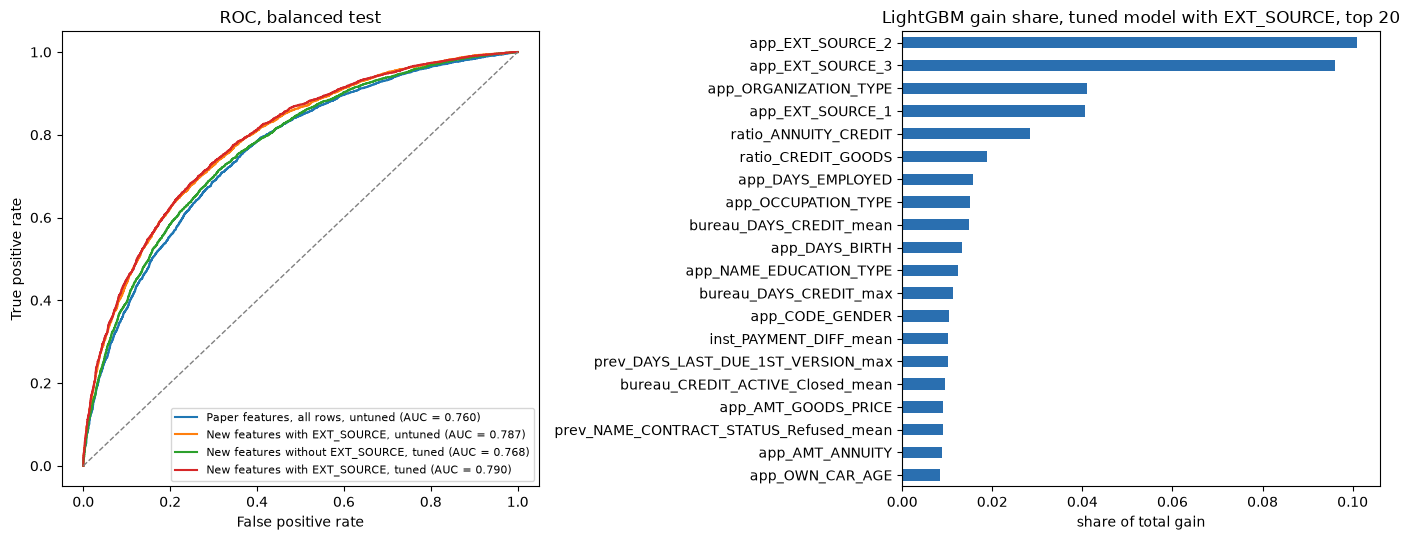

gain share: EXT_SOURCE 0.238 | ratios 0.066
ratio ranks: {'ratio_CREDIT_INCOME': 51, 'ratio_ANNUITY_INCOME': 26, 'ratio_ANNUITY_CREDIT': 5, 'ratio_CREDIT_GOODS': 6, 'ratio_EMPLOYED_BIRTH': 25, 'ratio_INCOME_PER_PERSON': 139}


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for n, r in res.items():
    fpr, tpr, _ = roc_curve(yt.loc[bal_ids], r["test"].loc[bal_ids]); ax[0].plot(fpr, tpr, lw=1.5, label=f"{n} (AUC = {sc[n]['balanced']['auc']:.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC, balanced test"); ax[0].legend(loc="lower right", fontsize=8)

g = res["New features with EXT_SOURCE, tuned"]["gain"]; g = g / g.sum()
g.nlargest(20)[::-1].plot.barh(ax=ax[1], color="#2a6fb0", title="LightGBM gain share, tuned model with EXT_SOURCE, top 20"); ax[1].set_xlabel("share of total gain")
plt.tight_layout(); plt.savefig(OUT / "figure_improved.png", dpi=150); plt.show()
print("gain share: EXT_SOURCE", round(g[ext].sum(), 3), "| ratios", round(g[ratio_cols].sum(), 3))
print("ratio ranks:", {c: int(g.rank(ascending=False)[c]) for c in ratio_cols})

**Findings.** In the tuned model the three `EXT_SOURCE` columns take 24% of the total gain out of 837 features. The six ratios take 6.6%, mostly `ratio_ANNUITY_CREDIT` (rank 5) and `ratio_CREDIT_GOODS` (rank 6); `ratio_INCOME_PER_PERSON` is not useful (rank 139).

## Notes

- **Scope:** this notebook is outside the paper's setup. The feature set with `EXT_SOURCE_1..3` uses columns the paper excludes, so it is not comparable with the paper's Table III; the one without them keeps that exclusion. `EXT_SOURCE_1` is missing for 56% of clients and `EXT_SOURCE_3` for 20%; LightGBM handles the gaps.
- **Protocol:** threshold from train out-of-fold predictions; 3 folds, one seed; test sets used only for the final scores. The search uses one 80/20 split with early stopping on the same rows it is scored on, so its validation AUC is slightly optimistic; the out-of-fold and test numbers are not affected. The model without `EXT_SOURCE` uses the configuration found with it; it was not searched separately.
- **Early stopping** tracks validation AUC only (`metric="auc"`). With a weighted positive class the default log-loss on the validation rows rises from the first round, and stopping on it ends training after one or two trees.
- **Outputs:** `artifacts/train_raw.parquet`, `test_raw.parquet`, `lgbm_search.csv`, `lgbm_best_params.json`, `table_improved.csv`, `figure_improved.png`.